# Student Reading Habits Analysis using Data Analytics

##Course: 602  Data Analytics using Python  
Project Type: Exploratory Data Analysis and Prediction using Python  

## Dataset
student_reading_habits.csv

## Objective
The objective of this project is to analyze student reading behaviour using
data analytics techniques such as exploratory data analysis, regression,
classification, and model evaluation.

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Seaborn
- Scikit-learn

## Student Reading Habits Analysis using Data Analytics

Course: 602 – Data Analytics using Python  

Project Type: Exploratory Data Analysis and Prediction using Python  

## Dataset

student_reading_habits.csv

## Objective

The objective of this project is to analyze student reading behaviour using

data analytics techniques such as exploratory data analysis, regression,

classification, and model evaluation.

## Tools Used

\- Python

\- Pandas

\- NumPy

\- Matplotlib

\- Seaborn

\- Scikit-learn


## Course: 602 – Data Analytics using Python  
Project Type: Exploratory Data Analysis and Prediction using Python  

## Dataset
student_reading_habits.csv

## Objective

In [46]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

sns.set(style="whitegrid")

## Task 1: Data Understanding

In this step we load the dataset and examine its structure.



In [48]:
df = pd.read_csv("student_reading_habits.csv")

# first 5 rows
df.head()

,Student_ID,Age,Gender,Study_Hours_Per_Day,Reading_Hours_Per_Week,Preferred_Genre,Device_Type,Library_Visits_Per_Month,Books_Read_Per_Month,Reading_Score,Reading_Level
0,1001,23,Female,2.1,20.9,Fantasy,E-Books,1,7,72.365125,Medium
1,1002,20,Male,3.7,21.7,Fiction,E-Books,10,5,62.554171,Medium
2,1003,24,Male,7.8,23.1,Fantasy,Audiobooks,6,1,64.197544,Medium
3,1004,21,Male,2.8,11.9,Fiction,Audiobooks,8,6,45.187630,Medium
4,1005,23,Male,5.6,9.3,Comics,E-Books,0,3,31.814960,Low


In [49]:
# last 5 rows
df.tail()

,Student_ID,Age,Gender,Study_Hours_Per_Day,Reading_Hours_Per_Week,Preferred_Genre,Device_Type,Library_Visits_Per_Month,Books_Read_Per_Month,Reading_Score,Reading_Level
995,1996,24,Male,2.9,19.9,Academic,Audiobooks,10,2,50.232660,Medium
996,1997,17,Male,3.1,19.5,Non-Fiction,Audiobooks,6,2,64.092071,Medium
997,1998,25,Female,6.5,6.3,Non-Fiction,Audiobooks,0,4,40.558190,Medium
998,1999,23,Female,4.1,4.0,Academic,E-Books,12,4,25.302267,Low
999,2000,19,Male,6.6,18.1,Academic,Audiobooks,1,9,86.687954,High


In [50]:
# dataset shape
df.shape

(1000, 11)

In [51]:
# column names
df.columns

Index(['Student_ID', 'Age', 'Gender', 'Study_Hours_Per_Day',
       'Reading_Hours_Per_Week', 'Preferred_Genre', 'Device_Type',
       'Library_Visits_Per_Month', 'Books_Read_Per_Month', 'Reading_Score',
       'Reading_Level'],
      dtype='object')

In [52]:
# dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Student_ID                1000 non-null   int64  
 1   Age                       1000 non-null   int64  
 2   Gender                    1000 non-null   object 
 3   Study_Hours_Per_Day       980 non-null    float64
 4   Reading_Hours_Per_Week    1000 non-null   float64
 5   Preferred_Genre           1000 non-null   object 
 6   Device_Type               1000 non-null   object 
 7   Library_Visits_Per_Month  1000 non-null   int64  
 8   Books_Read_Per_Month      1000 non-null   int64  
 9   Reading_Score             1000 non-null   float64
 10  Reading_Level             1000 non-null   object 
dtypes: float64(3), int64(4), object(4)
memory usage: 86.1+ KB


## Task 2: Exploratory Data Analysis (EDA)

EDA helps understand patterns and relationships in the dataset.

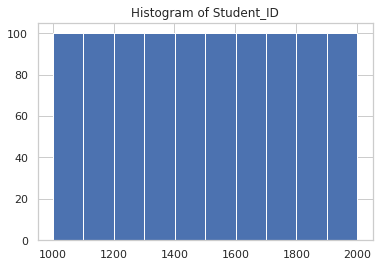

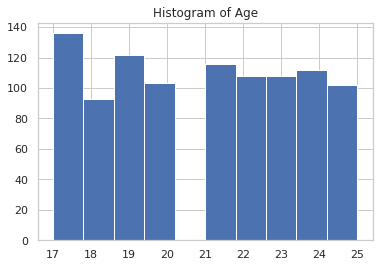

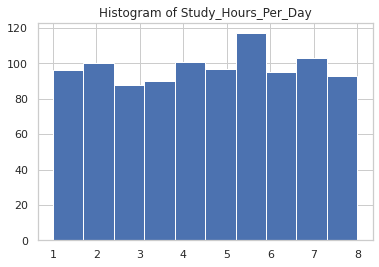

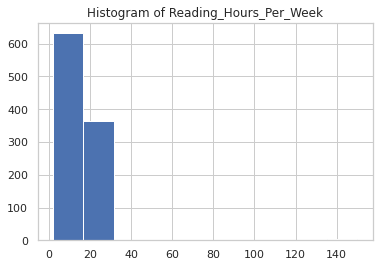

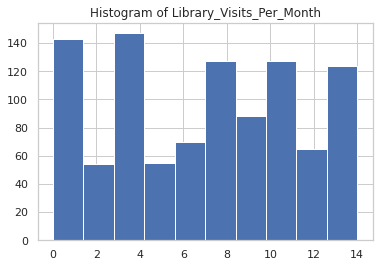

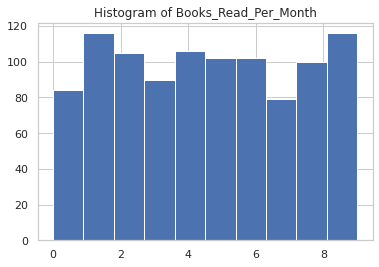

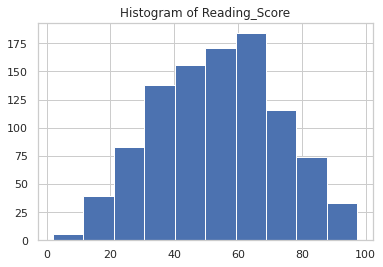

In [53]:
numeric_columns = df.select_dtypes(include=np.number).columns

for col in numeric_columns:
    plt.figure()
    plt.hist(df[col])
    plt.title(f"Histogram of {col}")
    plt.show()

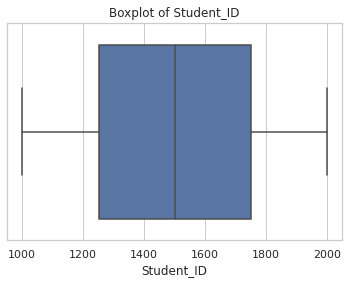

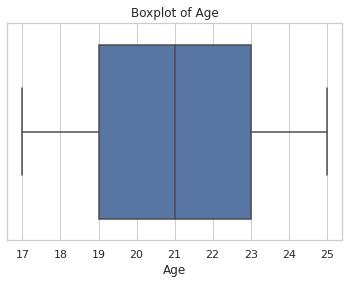

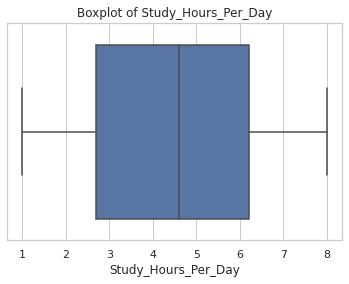

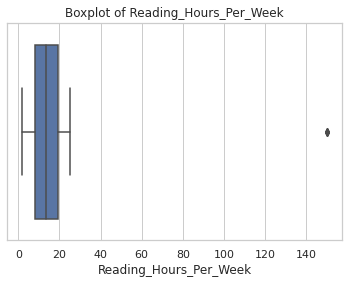

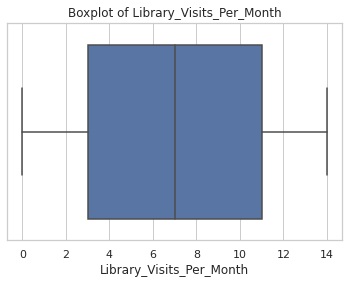

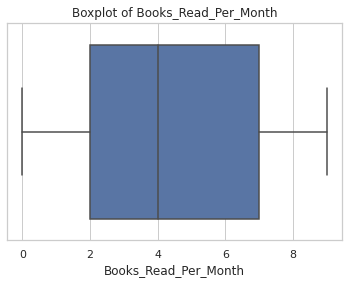

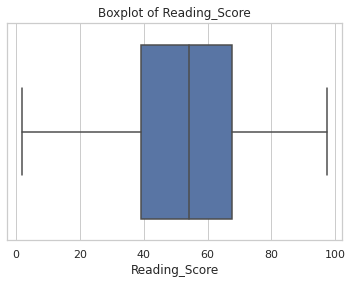

In [54]:
for col in numeric_columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

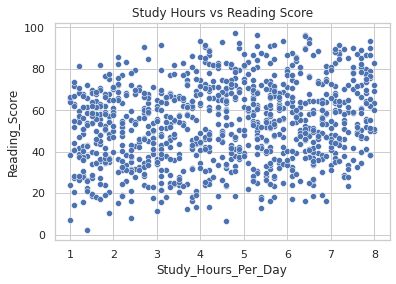

In [55]:
sns.scatterplot(x=df['Study_Hours_Per_Day'], y=df['Reading_Score'])
plt.title("Study Hours vs Reading Score")
plt.show()

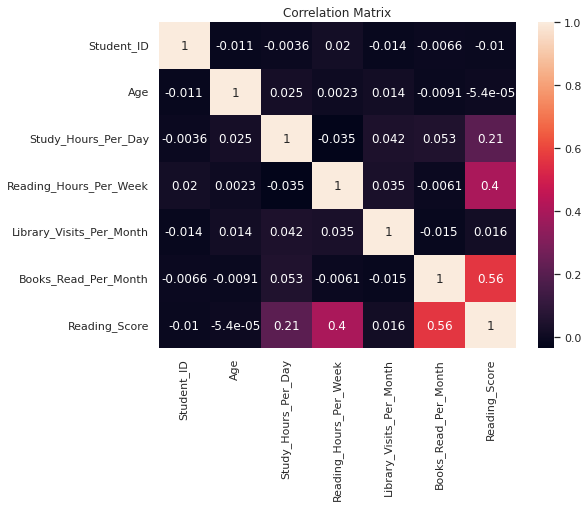

In [56]:
# select only numeric columns
numeric_df = df.select_dtypes(include=['number'])

# correlation matrix
corr_matrix = numeric_df.corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True)
plt.title("Correlation Matrix")
plt.show()

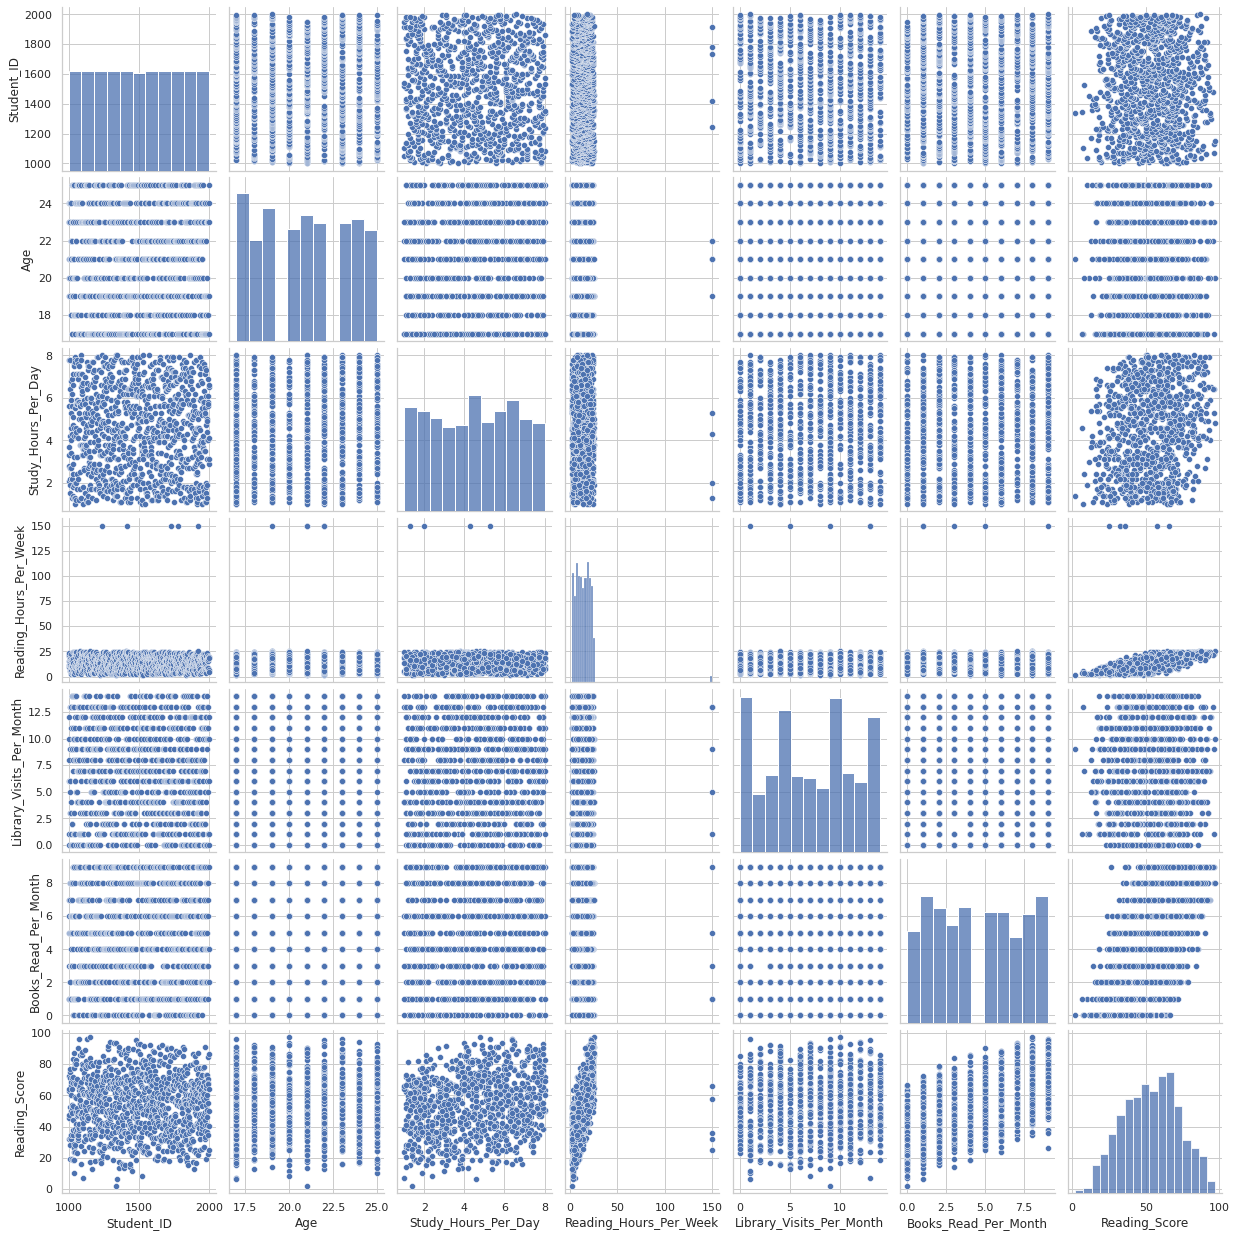

In [57]:
sns.pairplot(df[numeric_columns])
plt.show()

## Task 3: Handling Missing Data and Outliers

In [58]:
# check missing values
df.isnull().sum()

Student_ID                   0
Age                          0
Gender                       0
Study_Hours_Per_Day         20
Reading_Hours_Per_Week       0
Preferred_Genre              0
Device_Type                  0
Library_Visits_Per_Month     0
Books_Read_Per_Month         0
Reading_Score                0
Reading_Level                0
dtype: int64

In [59]:
# fill missing values if any
df.fillna(df.mean(numeric_only=True), inplace=True)

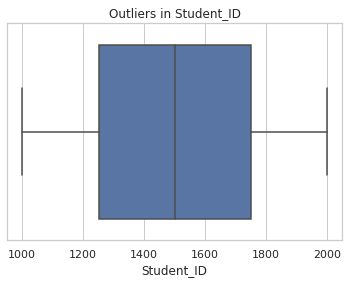

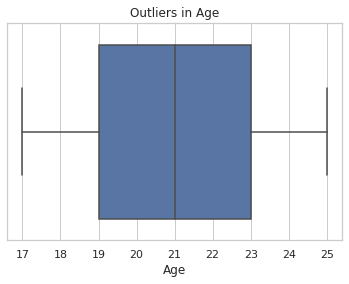

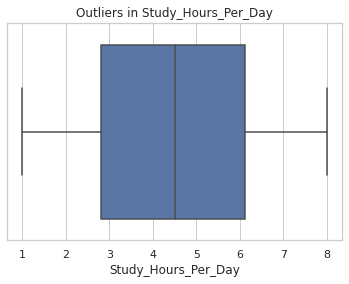

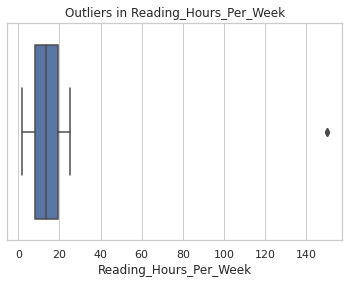

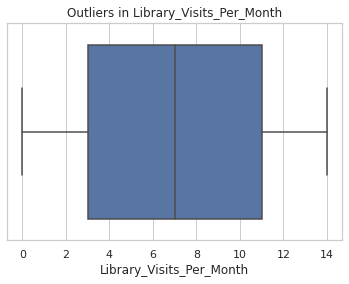

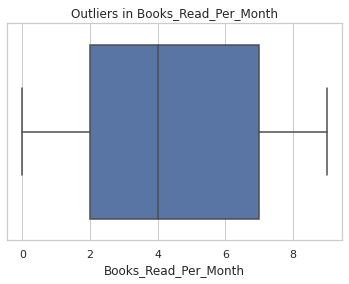

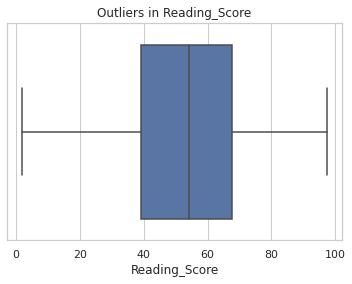

In [60]:
for col in numeric_columns:
    plt.figure()
    sns.boxplot(x=df[col])
    plt.title(f"Outliers in {col}")
    plt.show()

## Task 4: Spread of Data



In [61]:
df.describe()

,Student_ID,Age,Study_Hours_Per_Day,Reading_Hours_Per_Week,Library_Visits_Per_Month,Books_Read_Per_Month,Reading_Score
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,1500.500000,20.898000,4.485612,14.14740,6.924000,4.539000,53.545786
std,288.819436,2.603916,1.995287,11.67016,4.297056,2.887354,19.089574
min,1001.000000,17.000000,1.000000,2.00000,0.000000,0.000000,1.986224
25%,1250.750000,19.000000,2.800000,8.00000,3.000000,2.000000,39.106479
50%,1500.500000,21.000000,4.500000,13.50000,7.000000,4.000000,54.068297
75%,1750.250000,23.000000,6.125000,19.20000,11.000000,7.000000,67.763908
max,2000.000000,25.000000,8.000000,150.00000,14.000000,9.000000,97.353237


In [62]:
for col in numeric_columns:
    print("Column:", col)
    print("Mean:", df[col].mean())
    print("Median:", df[col].median())
    print("Std:", df[col].std())
    print("Skewness:", df[col].skew())
    print("Kurtosis:", df[col].kurt())
    print()

Column: Student_ID
Mean: 1500.5
Median: 1500.5
Std: 288.8194360957494
Skewness: 0.0
Kurtosis: -1.2

Column: Age
Mean: 20.898
Median: 21.0
Std: 2.603915585493578
Skewness: 0.017257771310358192
Kurtosis: -1.232019597682243

Column: Study_Hours_Per_Day
Mean: 4.485612244897956
Median: 4.5
Std: 1.995286521017477
Skewness: -0.02920212184108801
Kurtosis: -1.1479477679944552

Column: Reading_Hours_Per_Week
Mean: 14.147400000000017
Median: 13.5
Std: 11.670159633264062
Skewness: 7.854034845134772
Kurtosis: 89.64885273461049

Column: Library_Visits_Per_Month
Mean: 6.924
Median: 7.0
Std: 4.297055816333862
Skewness: -0.006495366188674569
Kurtosis: -1.198229035334805

Column: Books_Read_Per_Month
Mean: 4.539
Median: 4.0
Std: 2.8873544666036097
Skewness: 0.03705371465777216
Kurtosis: -1.235795095073152

Column: Reading_Score
Mean: 53.545785514226424
Median: 54.06829685657452
Std: 19.089573510883703
Skewness: -0.052115725197146606
Kurtosis: -0.6677908998435185



## Task 5: Automating EDA


In [20]:
df.describe()

,Student_ID,Age,Study_Hours_Per_Day,Reading_Hours_Per_Week,Library_Visits_Per_Month,Books_Read_Per_Month,Reading_Score
count,1000.000000,1000.000000,1000.000000,1000.00000,1000.000000,1000.000000,1000.000000
mean,1500.500000,20.898000,4.485612,14.14740,6.924000,4.539000,53.545786
std,288.819436,2.603916,1.995287,11.67016,4.297056,2.887354,19.089574
min,1001.000000,17.000000,1.000000,2.00000,0.000000,0.000000,1.986224
25%,1250.750000,19.000000,2.800000,8.00000,3.000000,2.000000,39.106479
50%,1500.500000,21.000000,4.500000,13.50000,7.000000,4.000000,54.068297
75%,1750.250000,23.000000,6.125000,19.20000,11.000000,7.000000,67.763908
max,2000.000000,25.000000,8.000000,150.00000,14.000000,9.000000,97.353237


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Student_ID                1000 non-null   int64  
 1   Age                       1000 non-null   int64  
 2   Gender                    1000 non-null   object 
 3   Study_Hours_Per_Day       1000 non-null   float64
 4   Reading_Hours_Per_Week    1000 non-null   float64
 5   Preferred_Genre           1000 non-null   object 
 6   Device_Type               1000 non-null   object 
 7   Library_Visits_Per_Month  1000 non-null   int64  
 8   Books_Read_Per_Month      1000 non-null   int64  
 9   Reading_Score             1000 non-null   float64
 10  Reading_Level             1000 non-null   object 
dtypes: float64(3), int64(4), object(4)
memory usage: 86.1+ KB


In [22]:
df.isnull().sum()

Student_ID                  0
Age                         0
Gender                      0
Study_Hours_Per_Day         0
Reading_Hours_Per_Week      0
Preferred_Genre             0
Device_Type                 0
Library_Visits_Per_Month    0
Books_Read_Per_Month        0
Reading_Score               0
Reading_Level               0
dtype: int64

In [45]:
numeric_df = df.select_dtypes(include='number')
numeric_df.corr()

,Student_ID,Age,Study_Hours_Per_Day,Reading_Hours_Per_Week,Library_Visits_Per_Month,Books_Read_Per_Month,Reading_Score
Student_ID,1.000000,-0.011457,-0.003603,0.019794,-0.013696,-0.006619,-0.010126
Age,-0.011457,1.000000,0.024937,0.002330,0.013531,-0.009056,-0.000054
Study_Hours_Per_Day,-0.003603,0.024937,1.000000,-0.032749,0.041996,0.052103,0.207444
Reading_Hours_Per_Week,0.019794,0.002330,-0.032749,1.000000,0.034938,-0.006071,0.400239
Library_Visits_Per_Month,-0.013696,0.013531,0.041996,0.034938,1.000000,-0.015090,0.016403
Books_Read_Per_Month,-0.006619,-0.009056,0.052103,-0.006071,-0.015090,1.000000,0.563236
Reading_Score,-0.010126,-0.000054,0.207444,0.400239,0.016403,0.563236,1.000000


In [24]:
def eda_summary(data):
    print("Shape:", data.shape)
    print("\nColumns:", data.columns)
    print("\nMissing Values:\n", data.isnull().sum())
    print("\nStatistics:\n", data.describe())

eda_summary(df)

Shape: (1000, 11)

Columns: Index(['Student_ID', 'Age', 'Gender', 'Study_Hours_Per_Day',
       'Reading_Hours_Per_Week', 'Preferred_Genre', 'Device_Type',
       'Library_Visits_Per_Month', 'Books_Read_Per_Month', 'Reading_Score',
       'Reading_Level'],
      dtype='object')

Missing Values:
 Student_ID                  0
Age                         0
Gender                      0
Study_Hours_Per_Day         0
Reading_Hours_Per_Week      0
Preferred_Genre             0
Device_Type                 0
Library_Visits_Per_Month    0
Books_Read_Per_Month        0
Reading_Score               0
Reading_Level               0
dtype: int64

Statistics:
         Student_ID          Age  Study_Hours_Per_Day  Reading_Hours_Per_Week  \
count  1000.000000  1000.000000          1000.000000              1000.00000   
mean   1500.500000    20.898000             4.485612                14.14740   
std     288.819436     2.603916             1.995287                11.67016   
min    1001.000000    17.0

## Task 6: Regression Analysis
Dependent Variable → Reading_Score  
Independent Variables → Study_Hours_Per_Day, Books_Read_Per_Month

In [25]:
X = df[['Study_Hours_Per_Day','Books_Read_Per_Month']]
y = df['Reading_Score']

In [26]:
np.cov(df['Study_Hours_Per_Day'], df['Reading_Score'])

array([[  3.9811683 ,   7.9013622 ],
       [  7.9013622 , 364.41181683]])

In [27]:
df[['Study_Hours_Per_Day','Reading_Score']].corr()

,Study_Hours_Per_Day,Reading_Score
Study_Hours_Per_Day,1.000000,0.207444
Reading_Score,0.207444,1.000000


## Task 7: Supervised Learning – Regression Model

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [29]:
model = LinearRegression()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

## Task 9: Overfitting and Underfitting

In [30]:
train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)

print("Training Score:", train_score)
print("Testing Score:", test_score)

Training Score: 0.35916380501741507
Testing Score: 0.30725283312662166


If training accuracy >> testing accuracy → overfitting
If both accuracies low → underfitting

## Task 10: Classification
Predict Reading Level

In [31]:
X = df[['Study_Hours_Per_Day','Books_Read_Per_Month']]
y = df['Reading_Level']

In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [33]:
classifier = LogisticRegression(max_iter=1000)

classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

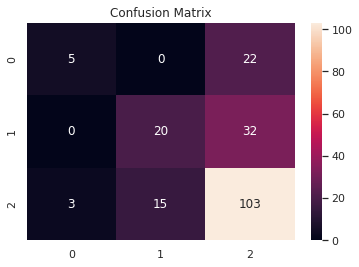

In [34]:
cm = confusion_matrix(y_test, y_pred)

plt.figure()
sns.heatmap(cm, annot=True, fmt="d")
plt.title("Confusion Matrix")
plt.show()

## Task 11: Model Evaluation

In [35]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Accuracy: 0.64

Classification Report:
               precision    recall  f1-score   support

        High       0.62      0.19      0.29        27
         Low       0.57      0.38      0.46        52
      Medium       0.66      0.85      0.74       121

    accuracy                           0.64       200
   macro avg       0.62      0.47      0.50       200
weighted avg       0.63      0.64      0.61       200



## Task 12: Model Evaluation Metrics

In [36]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.64
              precision    recall  f1-score   support

        High       0.62      0.19      0.29        27
         Low       0.57      0.38      0.46        52
      Medium       0.66      0.85      0.74       121

    accuracy                           0.64       200
   macro avg       0.62      0.47      0.50       200
weighted avg       0.63      0.64      0.61       200



## Task 13: Data Visualization

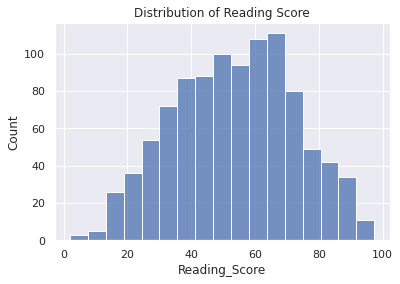

In [37]:
sns.histplot(df['Reading_Score'])
plt.title("Distribution of Reading Score")
plt.show()

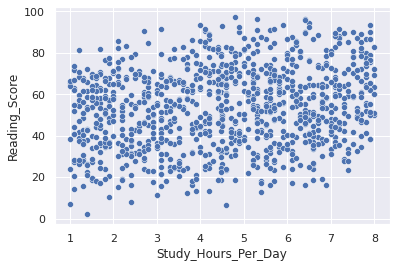

In [38]:
sns.scatterplot(x=df['Study_Hours_Per_Day'], y=df['Reading_Score'])
plt.show()

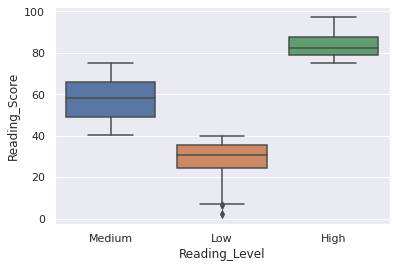

In [39]:
sns.boxplot(x=df['Reading_Level'], y=df['Reading_Score'])
plt.show()

## Conclusion

The Student Reading Habits Analysis using Data Analytics project was conducted to understand the reading behaviour, preferences, and patterns among students using data analytics techniques. The analysis was performed using Python tools such as Pandas, NumPy, Matplotlib, and Seaborn in a Jupyter Notebook environment.

The exploratory data analysis helped in understanding how different factors such as study hours, reading hours per week, number of books read per month, and library visits influence students' reading habits. The analysis indicated that students who spend more time reading or studying tend to develop stronger reading habits and achieve better reading scores. It also showed that regular reading and consistent engagement with books positively contribute to improved reading performance.

Different visualizations such as bar charts, histograms, and heatmaps were used to identify patterns and relationships within the dataset. The correlation analysis showed positive relationships between reading hours, books read per month, and reading scores, suggesting that increased reading activity leads to improved reading ability.

The study also highlighted differences in reading preferences and frequency among students. These insights can help educators and institutions encourage better reading practices by promoting reading programs, improving access to libraries, and motivating students to read regularly.

Overall, the project demonstrates how data analytics can be used to extract meaningful insights from educational data. The findings of this study can help support data-driven decision making in education and contribute to improving students’ reading habits and learning outcomes.